In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib_inline
from dataclasses import dataclass
import warnings
import seaborn as sns
from pygments.lexers import slash
from scipy.stats import (mannwhitneyu, binomtest, brunnermunzel,
                         ttest_ind, f, ks_2samp, iqr, levene)
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from greenbowl_mu import load_my_experiment, ALPHA, SLA_MIN, BUSINESS_MDE
from matplotlib.lines import Line2D
from statsmodels.stats.nonparametric import rank_compare_2indep

warnings.filterwarnings("ignore")
matplotlib_inline.backend_inline.set_matplotlib_formats('retina')

In [2]:
STUDENT_ID = "ozhelezniakovl@kse.org.ua"   # <-- put YOUR id here
exp = load_my_experiment(STUDENT_ID)

print(exp)                     # arm sizes
print(exp.data.head())         # one row per order: courier_id, arm, minutes
control, test = exp.control, exp.test

<Experiment n_control=700 n_test=703 metric=delivery minutes>
  courier_id      arm  minutes
0  c_3771967  control     41.0
1  c_7246983  control     31.0
2  c_8266320  control     40.0
3  c_3457924  control     27.0
4  c_0293952  control     40.0


In [3]:
exp.data

,courier_id,arm,minutes
0,c_3771967,control,41.0
1,c_7246983,control,31.0
2,c_8266320,control,40.0
3,c_3457924,control,27.0
4,c_0293952,control,40.0
...,...,...,...
1398,c_7396347,test,37.0
1399,c_3746856,test,9.0
1400,c_3528149,test,8.0
1401,c_4495124,test,60.0


# Design & Shape Forensics
---
* Створюємо функцію для опису та перевірки чи залеждні групи
* Бачимо, що групи незалежні
* Бачимо, що медіана та середні сході
* Будуємо графіки ECDF та histogram

In [4]:
def design_check(data: pd.DataFrame, arm_column: str, metric_column: str):
    test = data.query("arm == 'test'")
    control = data.query("arm == 'control'")

    @dataclass
    class DesignCheck:
        paired = test.merge(control, on=arm_column, how="inner").shape[0]

        mean_test = test[metric_column].mean()
        mean_control = control[metric_column].mean()

        median_test = test[metric_column].median()
        median_control = control[metric_column].median()

        skews_test = test[metric_column].skew()
        skews_control = control[metric_column].skew()

    return DesignCheck

## t-test

In [5]:
t_res = ttest_ind(control, test)

print("\t T-testt")
print(f"P-value: {t_res.pvalue:.3f}")
print(f"t-stat: {t_res.statistic:.3f}")
print(f"df: {t_res.df:.0f}")

	 T-testt
P-value: 0.510
t-stat: -0.658
df: 1401


In [6]:
check = design_check(exp.data, "arm", "minutes")

print("\t Check data")
print(f"Paired: {check.paired}")
print(f"Control mean: {check.mean_control:.3f} \t Test mean: {check.mean_test:.3f}")
print(f"Control median: {check.median_test:<4.0f} \t Test median: {check.median_control:.0f}")
print(f"Control skew: {check.skews_test:.3f} \t Test skew: {check.skews_control:.3f}")

	 Check data
Paired: 0
Control mean: 46.244 	 Test mean: 47.213
Control median: 41   	 Test median: 39
Control skew: 1.991 	 Test skew: 1.712


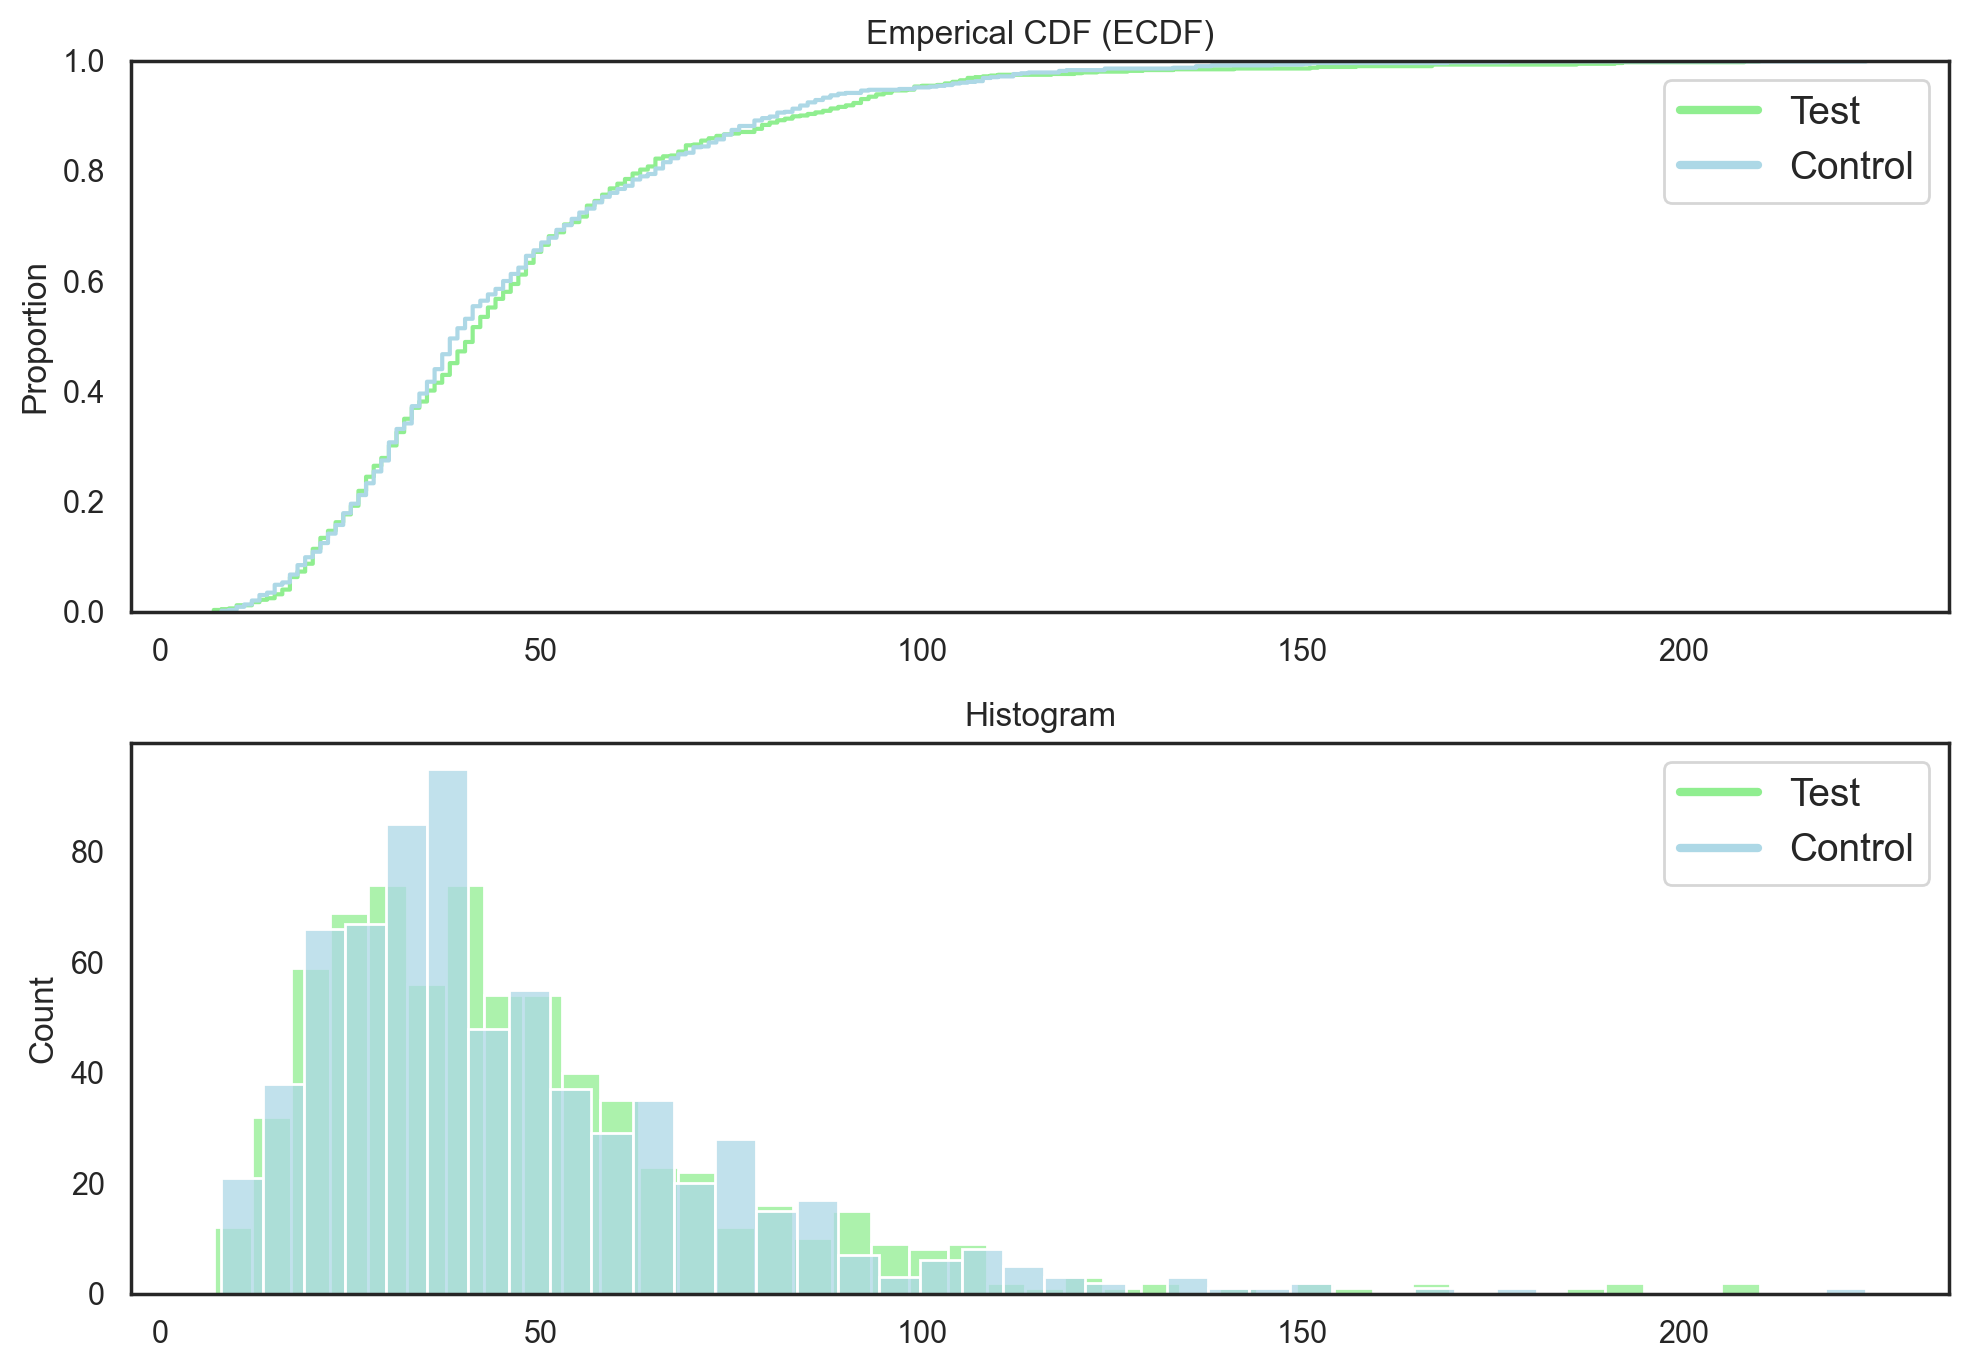

In [7]:
sns.set_theme(style="white")
fig, ax = plt.subplots(2, 1, figsize=(10, 7))

sns.ecdfplot(x=test, ax=ax[0], color="lightgreen")
sns.ecdfplot(x=control, ax=ax[0], color="lightblue")

sns.histplot(data=test, ax=ax[1], color="lightgreen", bins=40)
sns.histplot(data=control, ax=ax[1], color="lightblue", bins=40)

ax[0].set_title("Emperical CDF (ECDF)")
ax[1].set_title("Histogram")

legend_elements = [Line2D([0], [0], color="lightgreen", lw=3, label=f"Test"),
                   Line2D([0], [0], color="lightblue", lw=3, label="Control")]


plt.tight_layout()
ax[0].legend(handles=legend_elements, loc="upper right", fontsize=14)
ax[1].legend(handles=legend_elements, loc="upper right", fontsize=14)
plt.show()

#  Warm-up: the SLA Sign Test
---
* Створюэмо функцыю sign_test_median, яка рахує через біноміальний тест. Потім створюємо функцію sign_test_median_ztest, яка рахуює через z-тест
* Можемо бачити, p-value близько 1 та Z-stat завжди в CI

In [8]:
@dataclass
class SignTest:
    above: int
    p_value: float
    z_stat: float
    ci_low: float
    ci_high: float

def sign_test_median(x, m0, alternative="greater"):
    above = int((x > m0).sum())
    res   = binomtest(above, len(x), 0.5, alternative=alternative)
    res_ci = proportion_confint(above, len(x), 0.5, method="wilson")

    return SignTest(above, p_value=res.pvalue, z_stat=res.statistic,
                    ci_low=res_ci[0], ci_high=res_ci[1])


In [9]:
sign_test_result = sign_test_median(test, SLA_MIN)
print(f"\t Sign test SLA_MIN = {SLA_MIN}")
print(f"Above 45 minutes: {sign_test_result.above} from {len(test)}")
print(f"P-value: {sign_test_result.p_value:.5}")
print(f"Z-statistic: {sign_test_result.z_stat:.2f} above / all")
print(f"CI: {sign_test_result.ci_low:.3} -- 1")

	 Sign test SLA_MIN = 45
Above 45 minutes: 295 from 703
P-value: 0.99999
Z-statistic: 0.42 above / all
CI: 0.407 -- 1


In [10]:
def sign_test_median_ztest(x, m0, alternative="larger"):
    above = int((x > m0).sum())
    stat, pval = proportions_ztest(above, len(x), 0.5, alternative=alternative)
    res_ci = proportion_confint(above, len(x), 0.5, method="wilson")
    return SignTest(above, p_value=stat, z_stat=pval,
                    ci_low=res_ci[0], ci_high=res_ci[1])

In [11]:
binomtest_res = sign_test_median_ztest(test, SLA_MIN)
print("\t Sign test (from z-test)")
print(f"Above 45 minutes: {sign_test_result.above} from {len(test)}")
print(f"P-value: {sign_test_result.p_value:.5}")
print(f"Z-statistic: {sign_test_result.z_stat:.2f}")
print(f"CI: {sign_test_result.ci_low:.2f} -- 1")

	 Sign test (from z-test)
Above 45 minutes: 295 from 703
P-value: 0.99999
Z-statistic: 0.42
CI: 0.41 -- 1


In [12]:
@dataclass(slots=True)
class Reports:
    u_stat: float
    p_value: float
    p_hat: float
    verdict: str
    hl_shift: float
    ci_low: float
    ci_high: float

def mw_report(control, test,  alpha=0.05, alternative="greater"):
    """Version 1"""
    stat, p_value = mannwhitneyu(control, test, alternative=alternative)

    p_hat = stat / (len(control) * len(test))
    if p_value <= alpha:
        verdict = "⛔ reject -> there is differece in shift"
    else:
        verdict = "✅ do not reject -> there is no differece in shift"

    return Reports(u_stat=stat, p_value=p_value, p_hat=p_hat, verdict=verdict, hl_shift=None, ci_low=None, ci_high=None)


In [13]:
report_res = mw_report(control, test)

print("\t Manna Whitney U test")
print(f"P hat: {report_res.p_hat:.2f}")
print(f"U stat: {report_res.u_stat:.2f}")
print(f"P-value: {report_res.p_value:.5}")
print(f"Verdict: {report_res.verdict}")

	 Manna Whitney U test
P hat: 0.49
U stat: 242353.50
P-value: 0.68697
Verdict: ✅ do not reject -> there is no differece in shift


In [14]:
def ab_report(control, test,  alpha=0.05, alternative="greater"):
    """Version 2"""
    res = rank_compare_2indep(control, test)
    ci_low, ci_high = res.conf_int(alpha=0.05)

    diff = np.subtract.outer(control, test)
    hl_shift = np.median(diff)
    #mu = len(control) * len(test)
    #s =  mp.sqrt(len(control) * len(test) * (len(control) +  len(test) + 1) / 12)

    stat, p_value = mannwhitneyu(control, test, alternative=alternative)
    p_hat = stat / (len(control) * len(test))
    if p_value <= alpha:
        verdict = "⛔ reject -> there is differece in shift"
    else:
        verdict = "✅ do not reject -> there is no differece in shift"

    return Reports(u_stat=stat, p_value=p_value, p_hat=p_hat,
                   verdict=verdict, hl_shift=hl_shift, ci_low=ci_low, ci_high=ci_high)

In [15]:
report_res = ab_report(control, test)
print("\t Manna Whitney U test")
print(f"P hat: {report_res.p_hat:.2f}")
print(f"U stat: {report_res.u_stat:.2f}")
print(f"P-value: {report_res.p_value:.5f}")
print(f"Verdict: {report_res.verdict}")
print(f"Hodges–Lehmann: {report_res.hl_shift}")
print(f"CI: {report_res.ci_low:.2f} -- 1")

	 Manna Whitney U test
P hat: 0.49
U stat: 242353.50
P-value: 0.68697
Verdict: ✅ do not reject -> there is no differece in shift
Hodges–Lehmann: -1.0
CI: 0.46 -- 1


## Discrebe shape

In [16]:
def f_test(sample_1, sample_2):

    var1 = np.var(sample_1, ddof=1)
    var2 = np.var(sample_2, ddof=1)

    df1 = len(sample_1) - 1
    df2 = len(sample_2) - 1

    if var1 > var2:
        f_stat = var1 / var2
        p_value = f.sf(f_stat, df1, df2)
    else:
        f_stat = var2/ var1
        p_value = f.sf(f_stat, df2, df1)
    return {"f_stat": f_stat, "p_value": p_value}

### F-test між групами
---
* `reject`, скоріше за все, false positive через ненормальність

In [17]:
f_res = f_test(test, control)

print("\t f-test")
print(f"P-value: {f_res['f_stat']:.2f}")
print(f"F-stat: {f_res['p_value']:.3f}")
print("⛔ rejec different varience")

	 f-test
P-value: 1.13
F-stat: 0.049
⛔ rejec different varience


### Levene's test
---
* Критерій Левенса показує, що дисперсії однакові

In [18]:
levene_res = levene(test, control, center="median")

print("\t Levene's test")
print(f"P-value: {levene_res.pvalue:.2f}")
print(f"Statistic: {levene_res.statistic:.2f}")
print("✅ Don't rejec the same varience")

	 Levene's test
P-value: 0.61
Statistic: 0.27
✅ Don't rejec the same varience


In [19]:
iqr_test = iqr(test)
iqr_contol = iqr(control)

print(f"Contol IQR: {iqr_contol:.0f}")
print(f"Test IQR: {iqr_test:.0f}")

Contol IQR: 30
Test IQR: 30


### Kolmogorov-Smirnov test
---
* Показує, що розподіли гомогені

In [20]:
ks_res = ks_2samp(test, control)

print("\t  Kolmogorov-Smirnov test (homogeneity)")
print(f"D: {ks_res.statistic:.2f}")
print(f"P-value: {ks_res.pvalue:.2f}")

	  Kolmogorov-Smirnov test (homogeneity)
D: 0.04
P-value: 0.46


In [21]:
brunnermunzel_res = brunnermunzel(test, control)

print("\t Brunner-Munzel test")
print(f"P-value: {brunnermunzel_res.pvalue:.2f}")
print(f"Statistic: {brunnermunzel_res.statistic:.2f}")

	 Brunner-Munzel test
P-value: 0.63
Statistic: -0.49


# A/A test
---
* Перевіряємо валідність та шукаємо потужність

In [22]:
rng = np.random.default_rng()
variance = np.var(test, ddof=1)
mean = np.mean(test)
sigma_squared = np.log((variance / (mean ** 2)) + 1)
log_simu = lambda median, n: rng.lognormal(np.log(median), sigma_squared, size=n)
@dataclass
class Test_Valid:
    fpr: float
    ci_low: float
    ci_hight: float
def a_a_test(median, per_group = 200, genarator=log_simu, alpha=0.05, exp=10_000):
    """Is test valid?"""
    reject = 0
    for _ in range(exp):
        sample_1 = genarator(median, per_group)
        sample_2 = genarator(median, per_group)
        res = ab_report(sample_1, sample_2)
        reject += 1 if res.p_value <= alpha else 0
    fpr = reject/exp
    ci_low, ci_high = proportion_confint(reject, exp, method="wilson")

    return Test_Valid(fpr, ci_low, ci_high)


In [23]:
median = np.median(test)
test_valid_res = a_a_test(median)

print("\t A/A test")
print(f"Emperical FPr: {test_valid_res.fpr:.3f}")
print(f"FPR CI: {test_valid_res.ci_low:.3f} -- {test_valid_res.ci_hight:.3f}")

	 A/A test
Emperical FPr: 0.049
FPR CI: 0.045 -- 0.054



In [24]:
@dataclass(slots=True)
class TestPower:
    power: float
    ci_low: float
    ci_hight: float
def get_power(median, mde, per_group = 200, generator=log_simu, alpha=0.05, exp=10_000):
    """Get Power"""
    reject = 0
    for _ in range(exp):
        sample_1 = generator(median + mde, per_group)
        sample_2 = generator(median, per_group)
        res = ab_report(sample_1, sample_2)
        reject += 1 if res.p_value <= alpha else 0
    power = reject/exp
    ci_low, ci_high = proportion_confint(reject, exp, method="wilson")

    return TestPower(power, ci_low, ci_high)


In [25]:
median = np.median(test)
print("Power test")
print("MDE \t Power \t\t Power CI \t  Verdict")
for mde in range(2, 12, 2):
    res = get_power(median, mde)
    verdict = "✅" if (res.power > 0.8) else "⛔"
    print(f"{mde} \t\t {res.power:.3f} \t {res.ci_low:.4f} -- {res.ci_hight:.4f} \t {verdict}")

Power test
MDE 	 Power 		 Power CI 	  Verdict
2 		 0.444 	 0.4343 -- 0.4538 	 ⛔
4 		 0.906 	 0.9006 -- 0.9121 	 ✅
6 		 0.996 	 0.9947 -- 0.9971 	 ✅
8 		 1.000 	 0.9996 -- 1.0000 	 ✅
10 		 1.000 	 0.9996 -- 1.0000 	 ✅


In [26]:
@dataclass(slots = True)
class Test_Rejection:
    fpr_mw: float
    ci_low_mw: float
    ci_hight_mw: float
    fpr_bm: float
    ci_low_bm: float
    ci_hight_bm: float

def power_com_2test(median, n1, n2, exp=10_000,genarator=log_simu, alpha=0.05):
    reject_mw = 0
    reject_bm = 0
    for _ in range(exp):
        sample_1 = genarator(median, n1)
        sample_2 = genarator(median, n2)
        res = ab_report(sample_1, sample_2)
        brunnermunzel_res = brunnermunzel(sample_1, sample_2)
        reject_bm += 1 if brunnermunzel_res.pvalue <= alpha else 0
        reject_mw += 1 if res.p_value <= alpha else 0

    fpr_mw = reject_mw/exp
    fpr_bm = reject_bm/exp

    ci_low_mw, ci_high_mw = proportion_confint(reject_mw, exp, method="wilson")
    ci_low_bm, ci_high_bm = proportion_confint(reject_bm, exp, method="wilson")

    return Test_Rejection(fpr_mw, ci_low_mw, ci_high_mw, fpr_bm, ci_low_bm, ci_high_bm)

In [27]:
print("MW VS Brunner–Münzel")
print("N diff \t\t FPR MW \t CI MW \t\t\t\t FPR BM \t CI BM")
for n in [1.01, 1.05, 1.075, 1.1, 1.15, 1.2, 1.3, 1.5]:
    res = power_com_2test(50, 200, int(200 * n))
    print(f"{(n - 1):<7.0%} \t {res.fpr_mw:.3f} \t {res.ci_low_mw:.3f} -- {res.ci_hight_mw:.3f} \t\t {res.fpr_bm:.3f} \t {res.ci_low_bm:.3f} -- {res.ci_hight_bm:.3f}")


MW VS Brunner–Münzel
N diff 		 FPR MW 	 CI MW 				 FPR BM 	 CI BM
1%      	 0.049 	 0.045 -- 0.054 		 0.047 	 0.043 -- 0.052
5%      	 0.054 	 0.049 -- 0.058 		 0.055 	 0.051 -- 0.059
7%      	 0.051 	 0.046 -- 0.055 		 0.052 	 0.048 -- 0.056
10%     	 0.052 	 0.048 -- 0.057 		 0.051 	 0.047 -- 0.056
15%     	 0.045 	 0.041 -- 0.049 		 0.052 	 0.047 -- 0.056
20%     	 0.050 	 0.046 -- 0.054 		 0.051 	 0.047 -- 0.055
30%     	 0.051 	 0.047 -- 0.055 		 0.047 	 0.043 -- 0.051
50%     	 0.052 	 0.048 -- 0.056 		 0.052 	 0.048 -- 0.057


In [28]:
norm_simu = lambda sigma, n: rng.normal(0, sigma, n)
@dataclass
class Test_Rejection:
    fpr_mw: float
    ci_low_mw: float
    ci_hight_mw: float
    fpr_bm: float
    ci_low_bm: float
    ci_hight_bm: float

def power_com_2test_2v(sigma, sigma_2, exp=10_000, genarator=norm_simu, alpha=0.05):
    reject_mw = 0
    reject_bm = 0
    for _ in range(exp):
        sample_1 = genarator(sigma, 200)
        sample_2 = genarator(sigma_2, 200)
        res = ab_report(sample_1, sample_2)
        brunnermunzel_res = brunnermunzel(sample_1, sample_2)
        reject_bm += 1 if brunnermunzel_res.pvalue <= alpha else 0
        reject_mw += 1 if res.p_value <= alpha else 0

    fpr_mw = reject_mw/exp
    fpr_bm = reject_bm/exp

    ci_low_mw, ci_high_mw = proportion_confint(reject_mw, exp, method="wilson")
    ci_low_bm, ci_high_bm = proportion_confint(reject_bm, exp, method="wilson")

    return Test_Rejection(fpr_mw, ci_low_mw, ci_high_mw, fpr_bm, ci_low_bm, ci_high_bm)

In [29]:
print("MW VS Brunner–Münzel")
print("Sigma diff \t\t FPR MW \t CI MW \t\t\t\t FPR BM \t CI BM")
for n in [1.01, 1.05, 1.075, 1.1, 1.15, 1.2, 1.3, 1.5]:
    res = power_com_2test_2v(1, 1 * n)
    print(f"{(n - 1):<7.0%} \t {res.fpr_mw:.3f} \t {res.ci_low_mw:.3f} -- {res.ci_hight_mw:.3f} \t\t {res.fpr_bm:.3f} \t {res.ci_low_bm:.3f} -- {res.ci_hight_bm:.3f}")

MW VS Brunner–Münzel
Sigma diff 		 FPR MW 	 CI MW 				 FPR BM 	 CI BM
1%      	 0.049 	 0.045 -- 0.054 		 0.049 	 0.044 -- 0.053
5%      	 0.052 	 0.048 -- 0.056 		 0.050 	 0.046 -- 0.054
7%      	 0.049 	 0.045 -- 0.054 		 0.050 	 0.046 -- 0.054
10%     	 0.050 	 0.046 -- 0.055 		 0.049 	 0.045 -- 0.054
15%     	 0.051 	 0.047 -- 0.055 		 0.050 	 0.046 -- 0.055
20%     	 0.052 	 0.048 -- 0.056 		 0.050 	 0.045 -- 0.054
30%     	 0.052 	 0.048 -- 0.057 		 0.050 	 0.045 -- 0.054
50%     	 0.054 	 0.049 -- 0.058 		 0.049 	 0.045 -- 0.053


In [30]:
from joblib import Parallel, delayed